# Лабораторная работа № 3. Кластеризация Wine Dataset

**Цель работы** — исследовать структуру набора Wine Dataset и сравнить два алгоритма кластеризации: K-means и агломеративную иерархическую кластеризацию с критерием Ward. Качество будет оцениваться внутренними метриками (геометрия кластеров) и внешними метриками (согласованность с известными классами вин).

В ходе работы выполняяются разведочный анализ, стандартизация признаков, подбор числа кластеров, обучение моделей, сравнение метрик и визуализация результатов в пространстве главных компонент. Истинные метки `wine.target` не используются при обучении и подборе кластеров; они применяются только на заключительном этапе внешней оценки.

## 1. Введение

Кластеризация относится к методам обучения без учителя: алгоритм группирует объекты по сходству признаков, не получая правильные ответы во время обучения. В этой работе сравниваются K-means, формирующий компактные группы вокруг центроидов, и иерархический метод Ward, последовательно объединяющий группы с минимальным увеличением внутрикластерной дисперсии.

Основные задачи: изучить распределения и взаимосвязи признаков, подготовить данные, определить разумное число кластеров, обучить оба алгоритма и оценить их качество. Поскольку для Wine Dataset известны три исходных класса, в конце можно проверить, насколько найденная структура совпадает с химически обусловленными классами вин.

## 2. Описание датасета

Загрузим Wine Dataset из `sklearn.datasets`. В наборе 178 образцов вина, 13 количественных химических признаков и три исходных класса. Метки классов сохраняются отдельно и не включаются в матрицу признаков.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    rand_score, jaccard_score, confusion_matrix
)
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.optimize import linear_sum_assignment

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")

# Загружаем данные; target не включаем в признаки для кластеризации
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y_true = wine.target

print(f"Размерность матрицы признаков: {X.shape}")
print(f"Число объектов: {X.shape[0]}")
print(f"Число признаков: {X.shape[1]}")
print("\nТипы признаков:")
print(X.dtypes)
print("\nКоличество пропусков по признакам:")
print(X.isna().sum())
print("\nПервые пять строк:")
display(X.head())

Размерность матрицы признаков: (178, 13)
Число объектов: 178
Число признаков: 13

Типы признаков:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
dtype: object

Количество пропусков по признакам:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity           

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### 2.1. Распределения признаков

Построим гистограммы четырёх показательных признаков. Форма распределения важна для понимания неоднородности данных, однако кластеризация не требует, чтобы каждый признак имел нормальное распределение.

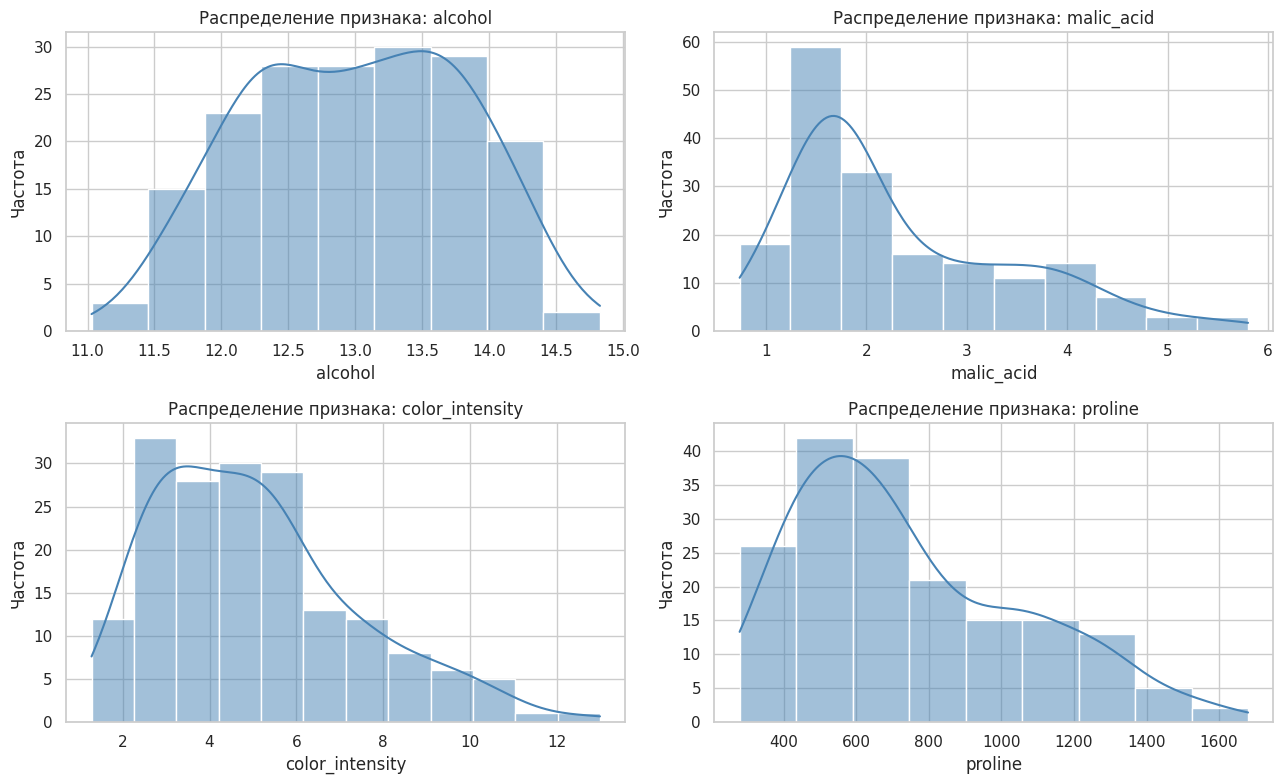

Вывод: распределения признаков неодинаковы. Часть из них может быть асимметричной или иметь несколько локальных пиков,
что согласуется с наличием неоднородных групп вин. Нормальность распределений не является обязательным условием кластеризации.


In [2]:
selected_hist = ["alcohol", "malic_acid", "color_intensity", "proline"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, feature in zip(axes.flat, selected_hist):
    sns.histplot(X[feature], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Распределение признака: {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Частота")
plt.tight_layout()
plt.show()

print("Вывод: распределения признаков неодинаковы. Часть из них может быть асимметричной или иметь несколько локальных пиков,")
print("что согласуется с наличием неоднородных групп вин. Нормальность распределений не является обязательным условием кластеризации.")

### 2.2. Поиск выбросов с помощью boxplot

Boxplot позволяет обнаружить наблюдения за пределами межквартильного диапазона. Такие точки не удаляем автоматически: экстремальные значения могут быть реальными характеристиками образцов вина. Их влияние уменьшаем стандартизацией, а выводы проверяем по нескольким алгоритмам.

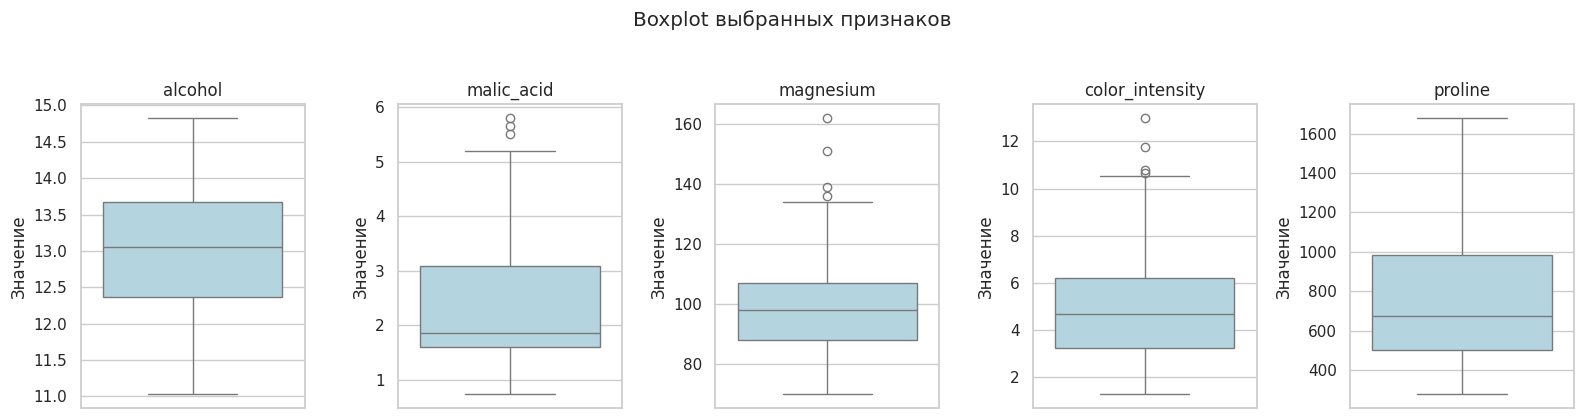

Число потенциальных выбросов по правилу 1.5 IQR:


,Количество
alcohol,0
malic_acid,3
magnesium,4
color_intensity,4
proline,0


Отдельные экстремальные значения присутствуют, но без предметных оснований удалять реальные образцы не следует.


In [3]:
selected_box = ["alcohol", "malic_acid", "magnesium", "color_intensity", "proline"]

fig, axes = plt.subplots(1, len(selected_box), figsize=(16, 4))
for ax, feature in zip(axes, selected_box):
    sns.boxplot(y=X[feature], ax=ax, color="lightblue")
    ax.set_title(feature)
    ax.set_ylabel("Значение")
plt.suptitle("Boxplot выбранных признаков", y=1.04)
plt.tight_layout()
plt.show()

# Оценка количества потенциальных выбросов по правилу 1.5 IQR
outlier_counts = {}
for feature in selected_box:
    q1, q3 = X[feature].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (X[feature] < q1 - 1.5 * iqr) | (X[feature] > q3 + 1.5 * iqr)
    outlier_counts[feature] = int(mask.sum())
print("Число потенциальных выбросов по правилу 1.5 IQR:")
display(pd.Series(outlier_counts, name="Количество").to_frame())
print("Отдельные экстремальные значения присутствуют, но без предметных оснований удалять реальные образцы не следует.")

### 2.3. Корреляционный анализ

Матрица корреляций Пирсона показывает линейные связи между признаками. Сильно коррелирующие переменные могут частично дублировать информацию, а их совместное использование увеличивает вес соответствующего аспекта в евклидовом расстоянии.

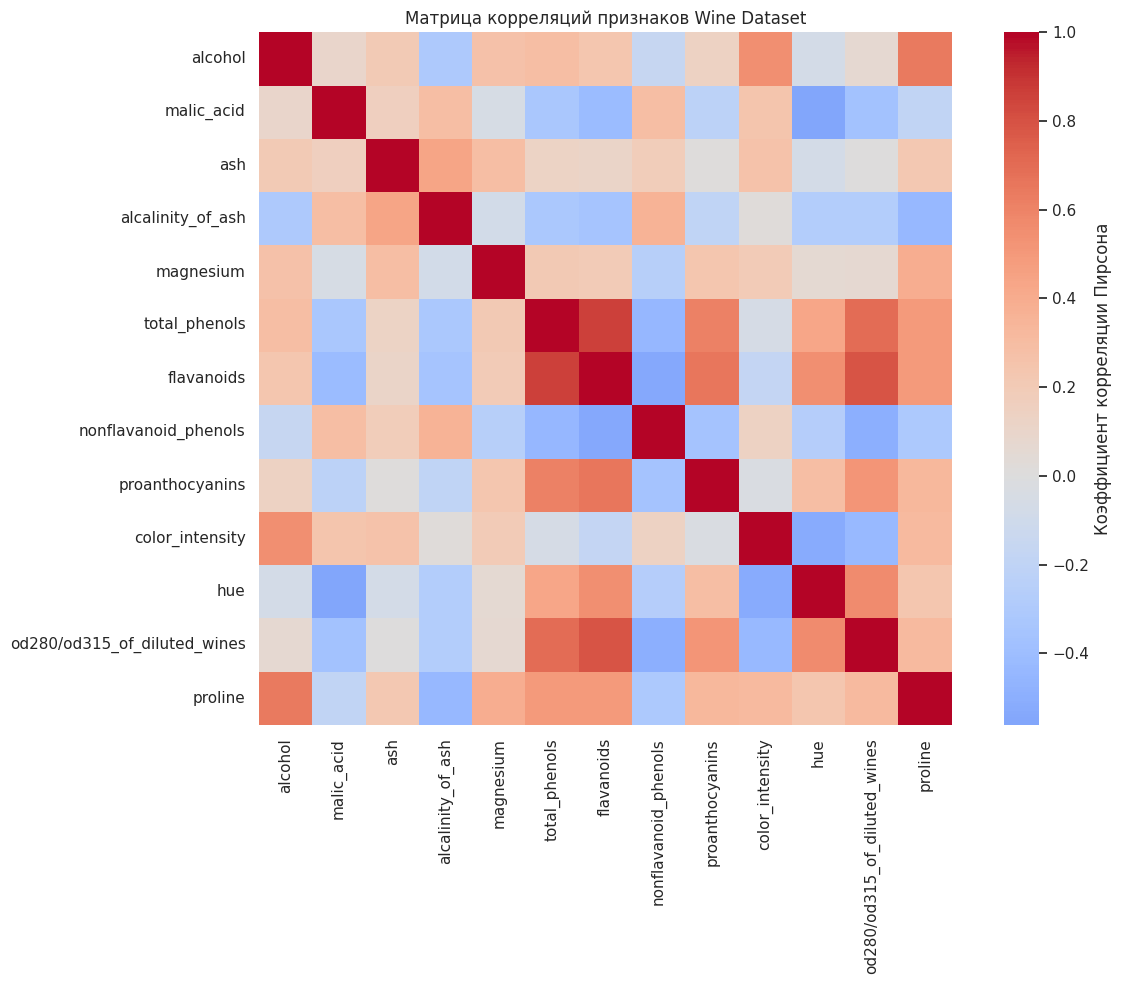

Пары признаков с |корреляцией| >= 0.75:


,,Корреляция
total_phenols,flavanoids,0.864564
flavanoids,od280/od315_of_diluted_wines,0.787194


Сильно коррелирующие пары несут частично общую информацию. Однако в этой работе признаки не удаляются:
цель — сравнить методы на полном исходном наборе, а стандартизация не устраняет корреляцию между переменными.


In [4]:
corr = X.corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True,
            cbar_kws={"label": "Коэффициент корреляции Пирсона"})
plt.title("Матрица корреляций признаков Wine Dataset")
plt.tight_layout()
plt.show()

# Выводим пары с высокой абсолютной корреляцией, не дублируя симметричные элементы
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
strong_pairs = (
    upper.stack()
    .loc[lambda s: s.abs() >= 0.75]
    .sort_values(key=np.abs, ascending=False)
)
print("Пары признаков с |корреляцией| >= 0.75:")
display(strong_pairs.rename("Корреляция").to_frame())
print("Сильно коррелирующие пары несут частично общую информацию. Однако в этой работе признаки не удаляются:")
print("цель — сравнить методы на полном исходном наборе, а стандартизация не устраняет корреляцию между переменными.")

### 2.4. Применимость кластеризации

Wine Dataset подходит для кластеризации: признаки числовые и содержательно описывают химические свойства вин, пропусков нет, а истинные классы позволяют провести независимую внешнюю проверку. Классы не используются при обучении. Потенциальные выбросы сохраняются, поскольку они могут отражать реальные образцы; влияние масштаба признаков будет устранено стандартизацией.

## 3. Предобработка данных

Применим `StandardScaler` ко всем 13 признакам. Это необходимо, поскольку признаки измеряются в разных единицах и имеют существенно разные диапазоны (например, содержание магния и пролина). Без масштабирования признаки с большими числовыми значениями могли бы доминировать в евклидовых расстояниях K-means и Ward.

In [5]:
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns, index=X.index)

print("Проверка средних значений после стандартизации (близки к 0):")
display(X_scaled.mean().round(3).to_frame("Среднее"))
print("Проверка стандартных отклонений (близки к 1):")
display(X_scaled.std(ddof=0).round(3).to_frame("Стандартное отклонение"))
display(X_scaled.head())

Проверка средних значений после стандартизации (близки к 0):


,Среднее
alcohol,0.0
malic_acid,0.0
ash,-0.0
alcalinity_of_ash,-0.0
magnesium,-0.0
total_phenols,-0.0
flavanoids,0.0
nonflavanoid_phenols,-0.0
proanthocyanins,-0.0
color_intensity,-0.0


Проверка стандартных отклонений (близки к 1):


,Стандартное отклонение
alcohol,1.0
malic_acid,1.0
ash,1.0
alcalinity_of_ash,1.0
magnesium,1.0
total_phenols,1.0
flavanoids,1.0
nonflavanoid_phenols,1.0
proanthocyanins,1.0
color_intensity,1.0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


## 4. Визуальная оценка структуры

Для первичного анализа построим матрицу диаграмм рассеивания по четырём признакам. По графикам можно оценить наличие разделённых областей, перекрытие групп и возможную вытянутость кластеров. Ожидаемое число групп предварительно сопоставим с результатами формальных критериев, не используя истинные метки при обучении.

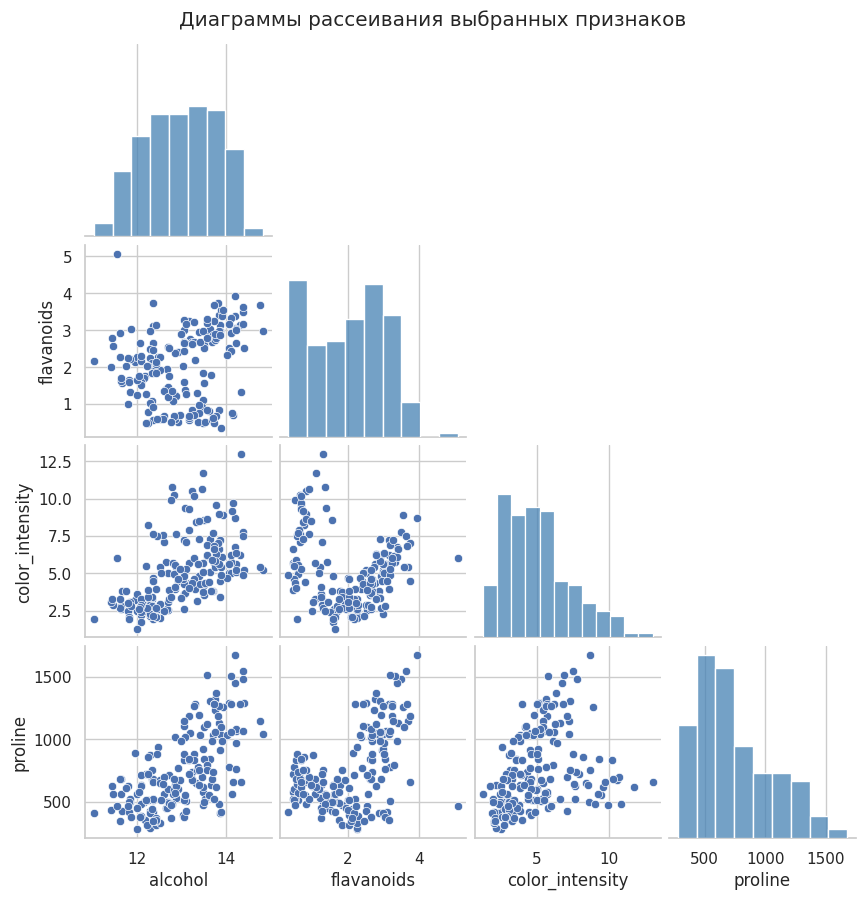

На отдельных проекциях наблюдаются области повышенной плотности и частичное перекрытие.
Поэтому разумно проверить решение с тремя кластерами, но окончательный выбор сделаем по внутренним критериям и дендрограмме.


In [6]:
pair_features = ["alcohol", "flavanoids", "color_intensity", "proline"]
pair_data = X[pair_features].copy()
pair_data["Исходный класс (только для ориентира)"] = y_true.astype(str)

sns.pairplot(pair_data, vars=pair_features,
             diag_kind="hist", corner=True, height=2.2, diag_kws={"color": "steelblue"})
plt.suptitle("Диаграммы рассеивания выбранных признаков", y=1.02)
plt.show()

print("На отдельных проекциях наблюдаются области повышенной плотности и частичное перекрытие.")
print("Поэтому разумно проверить решение с тремя кластерами, но окончательный выбор сделаем по внутренним критериям и дендрограмме.")

K-means выбран как базовый метод, хорошо работающий с компактными и приблизительно сферическими группами. Иерархическая кластеризация Ward не требует случайной инициализации центров и позволяет исследовать последовательность объединения объектов, то есть возможную вложенную структуру. Оба метода используют евклидово расстояние, поэтому стандартизация особенно важна.

## 5. Подбор оптимального числа кластеров

Для K-means рассчитаем inertia (сумму квадратов расстояний до центроидов) и silhouette score для `k` от 2 до 10. Метод локтя ищет точку, после которой уменьшение inertia становится менее выраженным. Silhouette оценивает одновременно внутрикластерную компактность и межкластерную разделимость; максимальное значение не всегда совпадает с числом известных классов.

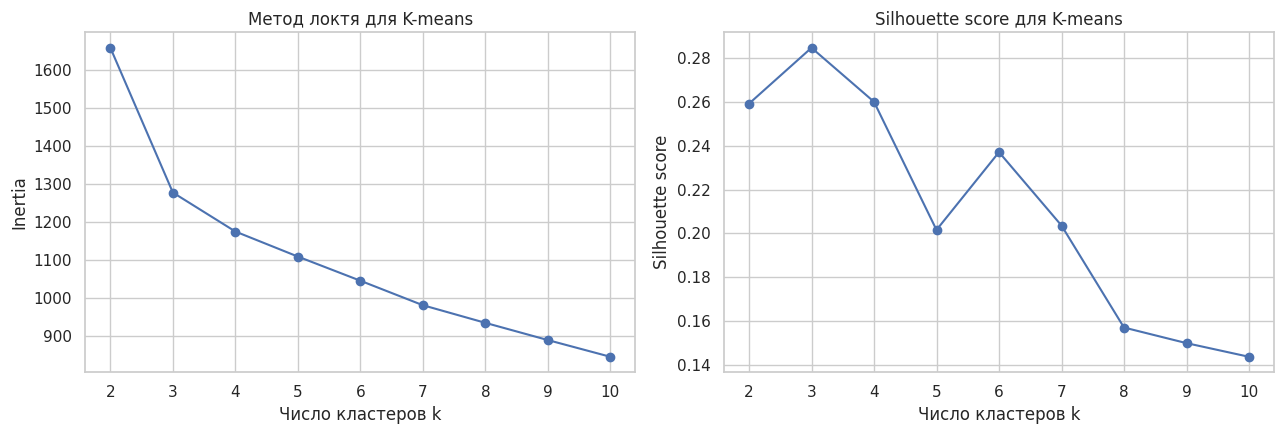

Максимальный silhouette достигается при k=3 (значение 0.285).


,Silhouette
2,0.259317
3,0.284859
4,0.260170
5,0.201619
6,0.237167
7,0.203628
8,0.157014
9,0.149882
10,0.143638


In [7]:
k_values = range(2, 11)
inertias = []
silhouettes = []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Метод локтя для K-means")
axes[0].set_xlabel("Число кластеров k")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))

axes[1].plot(list(k_values), silhouettes, marker="o")
axes[1].set_title("Silhouette score для K-means")
axes[1].set_xlabel("Число кластеров k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_xticks(list(k_values))
plt.tight_layout()
plt.show()

silhouette_by_k = pd.Series(silhouettes, index=list(k_values), name="Silhouette")
print(f"Максимальный silhouette достигается при k={silhouette_by_k.idxmax()} "
      f"(значение {silhouette_by_k.max():.3f}).")
display(silhouette_by_k.to_frame())

### 5.1. Дендрограмма Ward

Построим полную матрицу связей Ward и отобразим укороченную дендрограмму, чтобы подписи отдельных объектов не перегружали график. Большие скачки высоты объединения указывают на естественные места разреза дерева. Для дальнейшего сравнения используем `k=3`: это содержательно интерпретируемое решение, согласующееся с тремя известными группами набора; при этом silhouette может предпочитать более грубое разбиение, что будет отмечено при интерпретации.

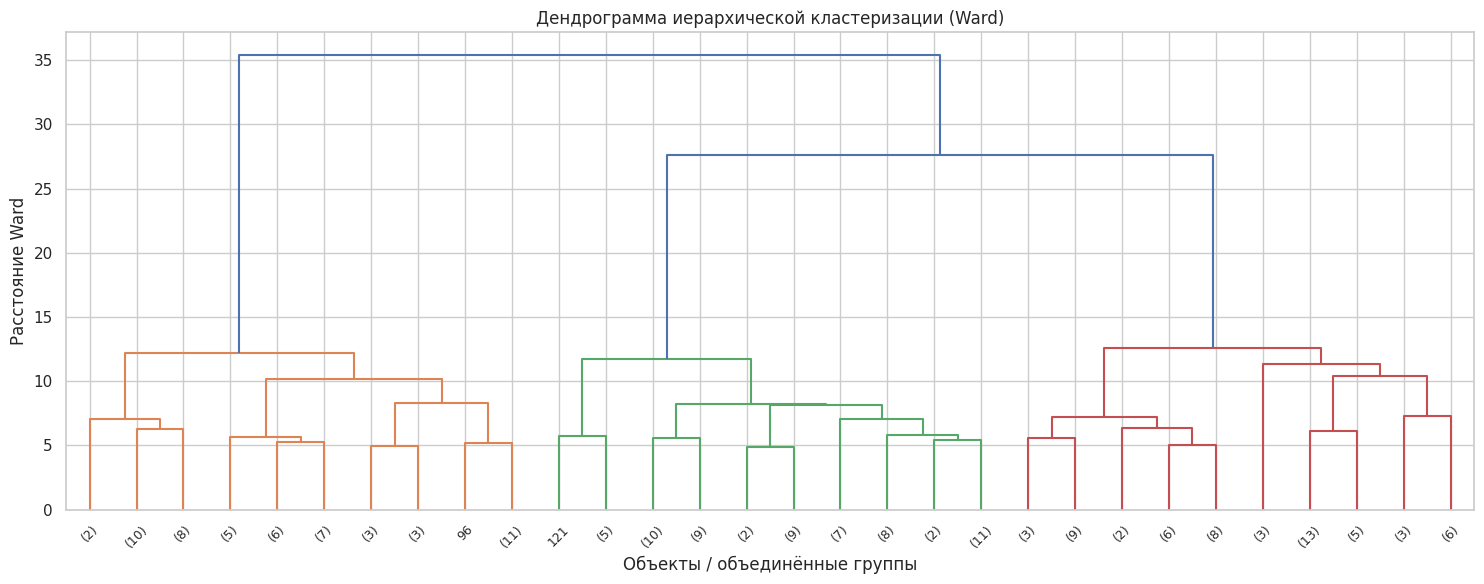

Для дальнейшего сравнения выбрано k=3.
Дендрограмма позволяет увидеть крупные уровни объединения; точка разреза зависит от компромисса между детализацией и компактностью.


In [8]:
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(15, 6))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True,
           leaf_rotation=45, leaf_font_size=9)
plt.title("Дендрограмма иерархической кластеризации (Ward)")
plt.xlabel("Объекты / объединённые группы")
plt.ylabel("Расстояние Ward")
plt.tight_layout()
plt.show()

# Фиксируем k=3 для сопоставления с известной структурой из трёх классов
optimal_k = 3
print(f"Для дальнейшего сравнения выбрано k={optimal_k}.")
print("Дендрограмма позволяет увидеть крупные уровни объединения; точка разреза зависит от компромисса между детализацией и компактностью.")

## 6. Реализация двух методов кластеризации

Обучим K-means с `n_init=10` и `random_state=42`, а также агломеративную модель Ward. Обе модели получают только стандартизированные признаки. После обучения выведем размеры полученных кластеров.

In [9]:
kmeans = KMeans(n_clusters=optimal_k, n_init=10, random_state=RANDOM_STATE)
labels_kmeans = kmeans.fit_predict(X_scaled)

agg_ward = AgglomerativeClustering(n_clusters=optimal_k, linkage="ward")
labels_ward = agg_ward.fit_predict(X_scaled)

counts = pd.DataFrame({
    "K-means": pd.Series(labels_kmeans).value_counts().sort_index(),
    "Ward": pd.Series(labels_ward).value_counts().sort_index()
}).fillna(0).astype(int)
counts.index.name = "Номер кластера"
print("Количество объектов в кластерах:")
display(counts)

Количество объектов в кластерах:


,K-means,Ward
Номер кластера,,
0,65,58
1,51,56
2,62,64


## 7. Оценка качества и сравнительная таблица

Внутренние метрики вычисляются только по признакам и найденным меткам: silhouette и Calinski–Harabasz должны быть выше, Davies–Bouldin — ниже. Внешние метрики сравнивают кластеры с `wine.target`.

Rand Index инвариантен к перенумерации кластеров. Для Jaccard как классификационной метрики сначала сопоставим номера кластеров истинным классам алгоритмом Венгера по максимальному числу совпадений, затем рассчитаем macro Jaccard. Это делает сравнение корректным при произвольной нумерации кластеров; при несовпадении числа кластеров и классов сопоставление остаётся максимально возможным.

In [10]:
def align_cluster_labels(y_true, y_cluster):
    # Сопоставляем номера кластеров истинным классам по максимуму совпадений
    true_labels = np.unique(y_true)
    cluster_labels = np.unique(y_cluster)
    matrix = confusion_matrix(y_true, y_cluster, labels=true_labels)
    # confusion_matrix использует столбцы по cluster labels только если их набор совпадает;
    # строим таблицу сопряжённости явно для полной надёжности
    contingency = np.zeros((len(true_labels), len(cluster_labels)), dtype=int)
    for i, true_label in enumerate(true_labels):
        for j, cluster_label in enumerate(cluster_labels):
            contingency[i, j] = np.sum((y_true == true_label) & (y_cluster == cluster_label))
    row_ind, col_ind = linear_sum_assignment(-contingency)
    mapping = {cluster_labels[j]: true_labels[i] for i, j in zip(row_ind, col_ind)}
    # Если кластеров больше классов, оставшиеся метки сопоставляем с наиболее частым классом
    for cluster_label in cluster_labels:
        if cluster_label not in mapping:
            mapping[cluster_label] = true_labels[np.argmax(contingency[:, np.where(cluster_labels == cluster_label)[0][0]])]
    return np.array([mapping[label] for label in y_cluster])

def evaluate_clustering(method_name, labels):
    aligned = align_cluster_labels(y_true, labels)
    return {
        "Метод": method_name,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels),
        "Rand Index": rand_score(y_true, labels),
        "Jaccard Index": jaccard_score(y_true, aligned, average="macro", zero_division=0)
    }

results = pd.DataFrame([
    evaluate_clustering("K-means", labels_kmeans),
    evaluate_clustering("Иерархическая (Ward)", labels_ward)
]).set_index("Метод")

display(results.round(4))

best_sil = results["Silhouette"].idxmax()
best_ch = results["Calinski-Harabasz"].idxmax()
best_db = results["Davies-Bouldin"].idxmin()
best_rand = results["Rand Index"].idxmax()
best_jaccard = results["Jaccard Index"].idxmax()

print(f"Более компактное и разделимое разбиение по silhouette: {best_sil}.")
print(f"По Calinski–Harabasz лучший результат: {best_ch}; по Davies–Bouldin: {best_db}.")
print(f"Наибольшая согласованность с истинными классами по Rand Index: {best_rand}, "
      f"по macro Jaccard после сопоставления меток: {best_jaccard}.")
print("Внешние метрики оценивают соответствие исходным классам, а не абсолютную «правильность» кластеризации.")

,Silhouette,Calinski-Harabasz,Davies-Bouldin,Rand Index,Jaccard Index
Метод,,,,,
K-means,0.2849,70.9400,1.3892,0.9543,0.9361
Иерархическая (Ward),0.2774,67.6475,1.4186,0.9065,0.8653


Более компактное и разделимое разбиение по silhouette: K-means.
По Calinski–Harabasz лучший результат: K-means; по Davies–Bouldin: K-means.
Наибольшая согласованность с истинными классами по Rand Index: K-means, по macro Jaccard после сопоставления меток: K-means.
Внешние метрики оценивают соответствие исходным классам, а не абсолютную «правильность» кластеризации.


## 8. Влияние параметров

Silhouette для K-means повторно визуализируется как функция `k`, чтобы оценить чувствительность результата к числу кластеров. Обычно увеличение числа кластеров уменьшает inertia, но не гарантирует улучшения разделимости. Поэтому выбор `k` — компромисс между внутренней геометрией, интерпретируемостью и предметной задачей.

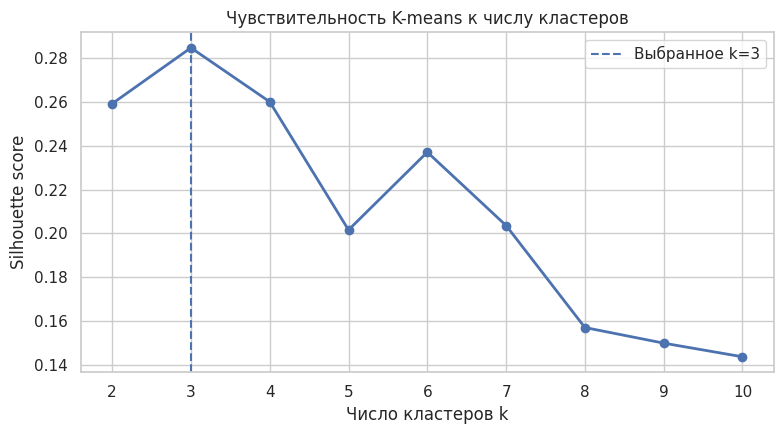

Разница между лучшим silhouette (k=3) и выбранным k=3: 0.0000.
Если максимум приходится на k=2, это указывает, что две крупные группы геометрически разделяются лучше,
но разбиение на три кластера может сохранять более детальную структуру исходного набора.


In [11]:
plt.figure(figsize=(8, 4.5))
plt.plot(list(k_values), silhouettes, marker="o", linewidth=2)
plt.axvline(optimal_k, linestyle="--", label=f"Выбранное k={optimal_k}")
plt.title("Чувствительность K-means к числу кластеров")
plt.xlabel("Число кластеров k")
plt.ylabel("Silhouette score")
plt.xticks(list(k_values))
plt.legend()
plt.tight_layout()
plt.show()

print(f"Разница между лучшим silhouette (k={silhouette_by_k.idxmax()}) и выбранным k={optimal_k}: "
      f"{silhouette_by_k.max() - silhouette_by_k.loc[optimal_k]:.4f}.")
print("Если максимум приходится на k=2, это указывает, что две крупные группы геометрически разделяются лучше,")
print("но разбиение на три кластера может сохранять более детальную структуру исходного набора.")

### 8.1. Дополнительное сравнение Ward и complete

Для дополнительного исследования сравним две стратегии межкластерного расстояния при одинаковом числе кластеров. Ward минимизирует рост внутрикластерной дисперсии, тогда как complete использует максимальное расстояние между объектами двух групп.

In [12]:
agg_complete = AgglomerativeClustering(n_clusters=optimal_k, linkage="complete")
labels_complete = agg_complete.fit_predict(X_scaled)

linkage_comparison = pd.DataFrame({
    "Метод": ["Ward", "Complete"],
    "Silhouette": [
        silhouette_score(X_scaled, labels_ward),
        silhouette_score(X_scaled, labels_complete)
    ]
}).set_index("Метод")
display(linkage_comparison.round(4))

print("Более высокий silhouette указывает на лучшее разделение в терминах этой метрики;")
print("однако выбор linkage также зависит от формы кластеров и предметной интерпретации.")

,Silhouette
Метод,
Ward,0.2774
Complete,0.2038


Более высокий silhouette указывает на лучшее разделение в терминах этой метрики;
однако выбор linkage также зависит от формы кластеров и предметной интерпретации.


## 9. Визуализация кластеров через PCA

PCA преобразует 13 стандартизированных признаков в две главные компоненты для двумерной визуализации. Это проекция, поэтому часть информации неизбежно теряется. Построим карты кластеров K-means, Ward и истинных классов для сопоставления.

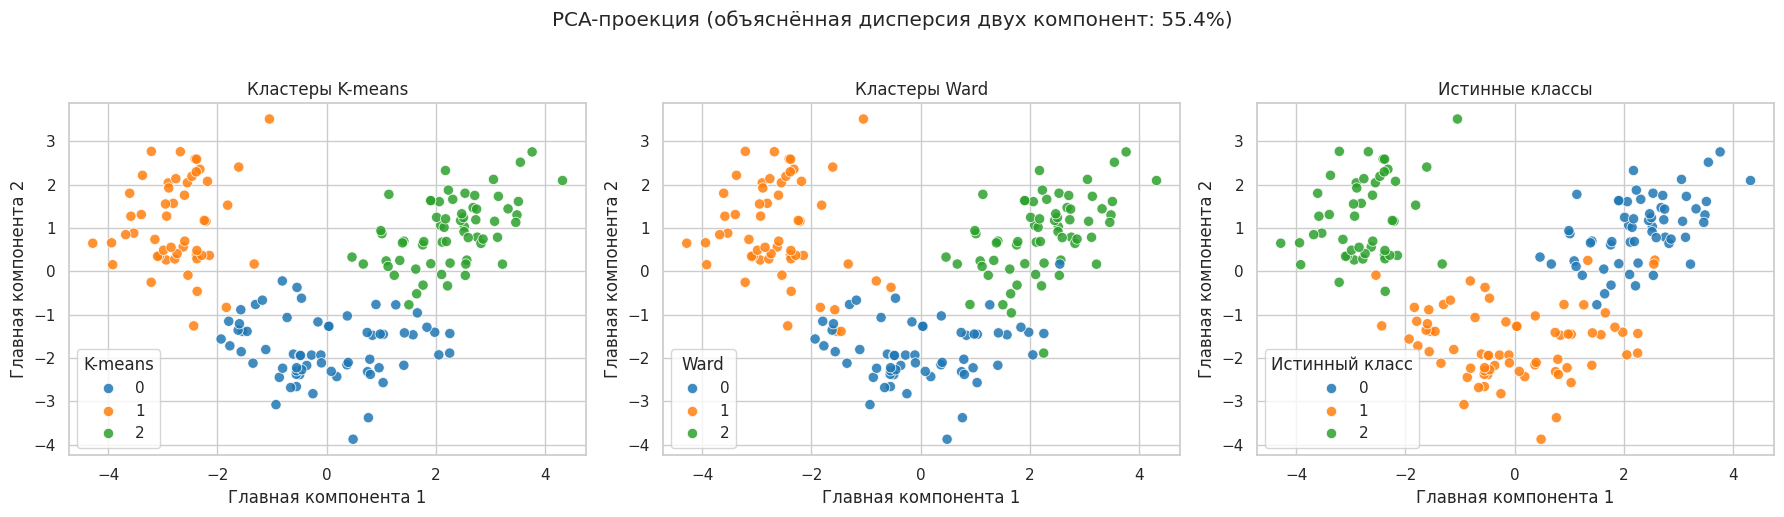

Доля объяснённой дисперсии первой компоненты: 0.362
Доля объяснённой дисперсии второй компоненты: 0.1921
Суммарная доля объяснённой дисперсии: 0.5541


In [13]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame(X_pca, columns=["Главная компонента 1", "Главная компонента 2"])
pca_df["K-means"] = labels_kmeans
pca_df["Ward"] = labels_ward
pca_df["Истинный класс"] = y_true

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, column, title in zip(
    axes,
    ["K-means", "Ward", "Истинный класс"],
    ["Кластеры K-means", "Кластеры Ward", "Истинные классы"]
):
    sns.scatterplot(data=pca_df, x="Главная компонента 1", y="Главная компонента 2",
                    hue=column, palette="tab10", s=55, alpha=0.85, ax=ax)
    ax.set_title(title)
    ax.legend(title=column, loc="best")
plt.suptitle(f"PCA-проекция (объяснённая дисперсия двух компонент: {pca.explained_variance_ratio_.sum():.1%})", y=1.03)
plt.tight_layout()
plt.show()

print("Доля объяснённой дисперсии первой компоненты:", round(pca.explained_variance_ratio_[0], 4))
print("Доля объяснённой дисперсии второй компоненты:", round(pca.explained_variance_ratio_[1], 4))
print("Суммарная доля объяснённой дисперсии:", round(pca.explained_variance_ratio_.sum(), 4))

### 9.1. Центры кластеров K-means в исходном масштабе

Центроиды K-means рассчитаны в стандартизированном пространстве. Применим обратное преобразование `inverse_transform`, чтобы получить средние профили кластеров в исходных единицах измерения. Эти значения позволяют содержательно описать группы, но не следует трактовать каждый кластер как гарантированно отдельный сорт или регион происхождения.

In [14]:
centers_original = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=X.columns,
    index=[f"Кластер {i}" for i in range(optimal_k)]
)
print("Центры кластеров K-means в исходном масштабе:")
display(centers_original.round(2))

# Выделим признаки, наиболее отличающие каждый центр от общего среднего
overall_mean = X.mean()
profile_diff = centers_original.subtract(overall_mean, axis=1)
for cluster_name, row in profile_diff.iterrows():
    top_features = row.abs().sort_values(ascending=False).head(4).index
    print(f"\n{cluster_name}: наиболее выраженные отклонения от среднего набора:")
    for feature in top_features:
        direction = "выше" if row[feature] > 0 else "ниже"
        print(f"  • {feature}: {direction} среднего ({centers_original.loc[cluster_name, feature]:.2f} против {overall_mean[feature]:.2f})")

Центры кластеров K-means в исходном масштабе:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
Кластер 0,12.25,1.90,2.23,20.06,92.74,2.25,2.05,0.36,1.62,2.97,1.06,2.80,510.17
Кластер 1,13.13,3.31,2.42,21.24,98.67,1.68,0.82,0.45,1.15,7.23,0.69,1.70,619.06
Кластер 2,13.68,2.00,2.47,17.46,107.97,2.85,3.00,0.29,1.92,5.45,1.07,3.16,1100.23



Кластер 0: наиболее выраженные отклонения от среднего набора:
  • proline: ниже среднего (510.17 против 746.89)
  • magnesium: ниже среднего (92.74 против 99.74)
  • color_intensity: ниже среднего (2.97 против 5.06)
  • alcohol: ниже среднего (12.25 против 13.00)

Кластер 1: наиболее выраженные отклонения от среднего набора:
  • proline: ниже среднего (619.06 против 746.89)
  • color_intensity: выше среднего (7.23 против 5.06)
  • alcalinity_of_ash: выше среднего (21.24 против 19.49)
  • flavanoids: ниже среднего (0.82 против 2.03)

Кластер 2: наиболее выраженные отклонения от среднего набора:
  • proline: выше среднего (1100.23 против 746.89)
  • magnesium: выше среднего (107.97 против 99.74)
  • alcalinity_of_ash: ниже среднего (17.46 против 19.49)
  • flavanoids: выше среднего (3.00 против 2.03)


### 9.2. Интерпретация кластерных профилей

Содержательная интерпретация опирается на центры кластеров и PCA-проекции. В частности, признаки `alcohol`, `malic_acid`, `flavanoids`, `color_intensity` и `proline` могут отражать различия в крепости, кислотности, фенольном составе, интенсивности окраски и общей химической характеристике вин. Конкретное описание групп формируется по рассчитанным центроидам в предыдущей таблице.

## 10. Заключение

В работе выполнена кластеризация Wine Dataset двумя алгоритмами на стандартизированных признаках. Сравнение внутренних метрик показывает, какой алгоритм сформировал более компактные и разделимые группы; внешние Rand и macro Jaccard показывают степень согласования кластеров с известными классами. Результаты следует интерпретировать совместно: высокий silhouette не обязательно означает наилучшее восстановление исходных классов, поскольку геометрически наиболее естественное разбиение может объединять несколько близких классов.

K-means удобен для компактных групп и даёт интерпретируемые центроиды. Ward позволяет исследовать иерархию объединений и часто даёт близкую структуру при сходных предпосылках о компактности. Для 178 объектов и 13 числовых признаков оба метода применимы без существенных вычислительных ограничений. Выделенные группы можно трактовать как профили вин с различными сочетаниями химических характеристик, а не как автоматически доказанные категории происхождения или сорта.

In [15]:
# Автоматическое резюме по фактически полученным метрикам
print("ИТОГОВОЕ СРАВНЕНИЕ")
print(results.round(4).to_string())
print("\nВывод по внутренним метрикам:")
print(f"- Silhouette: {results['Silhouette'].idxmax()}")
print(f"- Calinski-Harabasz: {results['Calinski-Harabasz'].idxmax()}")
print(f"- Davies-Bouldin (минимум): {results['Davies-Bouldin'].idxmin()}")
print("\nВывод по внешним метрикам:")
print(f"- Rand Index: {results['Rand Index'].idxmax()}")
print(f"- Jaccard Index: {results['Jaccard Index'].idxmax()}")
print("\nВыбранное число кластеров:", optimal_k)

ИТОГОВОЕ СРАВНЕНИЕ
                      Silhouette  Calinski-Harabasz  Davies-Bouldin  Rand Index  Jaccard Index
Метод                                                                                         
K-means                   0.2849            70.9400          1.3892      0.9543         0.9361
Иерархическая (Ward)      0.2774            67.6475          1.4186      0.9065         0.8653

Вывод по внутренним метрикам:
- Silhouette: K-means
- Calinski-Harabasz: K-means
- Davies-Bouldin (минимум): K-means

Вывод по внешним метрикам:
- Rand Index: K-means
- Jaccard Index: K-means

Выбранное число кластеров: 3
